# BN pool-size sensitivity analysis

This notebook provides a concise justification for the number of forward samples used to create the household BN pool. At each candidate size it generates ten independent pools, compares their attribute marginals with the exact BN-implied marginals using Total Variation Distance (TVD), records state coverage, and then discards the sampled records.

The selected size should be the smallest size after which average TVD, between-run variability, and state coverage show little meaningful improvement.

In [17]:
%load_ext autoreload
%autoreload 2

import gc
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import numpy as np
import pandas as pd
from pgmpy.inference import VariableElimination

from PopSynthesis.Methods.BN.utils.bn_pool import (
    file_sha256,
    load_bn_artifact,
    sample_condensed_pool,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Configuration

The experiment includes the smaller diagnostic sizes and the practical one-to-five-million range. The main plot uses the true linear pool-size scale; inset plots provide a readable zoom of the 10,000-to-500,000 range.

In [18]:
REPO_ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "pyproject.toml").exists()
)

MODEL_FILE = REPO_ROOT / "IO/models/hh_bn/household_bn.xml"
MODEL_METADATA_FILE = MODEL_FILE.with_suffix(".metadata.json")
RESULTS_FILE = REPO_ROOT / "IO/output/bn_pool_size_sensitivity.csv"
EXPERIMENT_METADATA_FILE = REPO_ROOT / "IO/output/bn_pool_size_sensitivity_metadata.json"

ATTRIBUTES = ["dwelltype", "owndwell", "hhinc", "totalvehs", "hhsize"]
POOL_SIZES = [
    10_000,
    50_000,
    100_000,
    250_000,
    500_000,
    1_000_000,
    2_000_000,
    3_000_000,
    4_000_000,
    5_000_000,
]
N_REPLICATES = 10
CHUNK_SIZE = 100_000
BASE_SEED = 42
RUN_EXPERIMENT = True

if POOL_SIZES != sorted(set(POOL_SIZES)) or any(size <= 0 for size in POOL_SIZES):
    raise ValueError("POOL_SIZES must be unique, increasing positive integers")
if N_REPLICATES <= 1:
    raise ValueError("N_REPLICATES must be greater than one")

## Exact BN marginals

TVD for attribute $A$ is $\frac{1}{2}\sum_s |\hat p_A(s)-p_A(s)|$, where $p_A$ is obtained directly from the stored BN and $\hat p_A$ is calculated from the sampled condensed pool.

In [19]:
model = load_bn_artifact(MODEL_FILE)
missing_attributes = set(ATTRIBUTES) - set(model.nodes())
if missing_attributes:
    raise ValueError(f"Stored BN is missing attributes: {sorted(missing_attributes)}")

inference = VariableElimination(model)
bn_marginals = {}
for attribute in ATTRIBUTES:
    marginal = inference.query([attribute], show_progress=False)
    bn_marginals[attribute] = pd.Series(
        marginal.values.astype(float),
        index=pd.Index(marginal.state_names[attribute], name=attribute),
        name="bn_probability",
    )

display(pd.concat(bn_marginals, names=["attribute", "state"]).to_frame())

bn_probability
attribute state                            
dwelltype Flat or Apartment        0.137556
          Missing                  0.001171
          Other                    0.035089
          Separate House           0.707858
          Terrace/Townhouse        0.118327
owndwell  Being Purchased          0.327430
          Being Rented             0.264544
          Fully Owned              0.384273
          Something Else           0.023754
hhinc     1-149                    0.011572
          1000-1249                0.082361
          1250-1499                0.077366
          150-299                  0.021401
          1500-1749                0.050464
          1750-1999                0.071257
          2000-2499                0.093137
          2500-2999                0.095158
          300-399                  0.031269
          3000-3499                0.052717
          3500-3999                0.045046
          400-499                  0.032406
          4000-4499                0.023686
          4500-4999                0.020860
          500-649                  0.060262
          5000-5999                0.029021
          6000-7999                0.016345
          650-799                  0.062533
          800-999                  0.063691
          8000+                    0.005760
          Nil income               0.051074
          Negative income          0.002612
totalvehs 0                        0.080120
          1                        0.379380
          2                        0.373461
          3                        0.110426
          4+                       0.056614
hhsize    1                        0.245292
          2                        0.342204
          3                        0.158804
          4                        0.164800
          5                        0.059645
          6                        0.016782
          7                        0.004295
          8+                       0.008179

## Run the sensitivity experiment

Only the condensed pool exists temporarily in memory. Each replicate/size result is reduced to TVD and coverage statistics before the next draw.

In [20]:
def calculate_pool_metrics(condensed_pool, pool_size, replicate):
    rows = []
    for attribute in ATTRIBUTES:
        sampled_counts = (
            condensed_pool.groupby(attribute, dropna=False)["count"]
            .sum()
            .reindex(bn_marginals[attribute].index, fill_value=0)
            .astype("int64")
        )
        sampled_probability = sampled_counts / pool_size
        tvd = 0.5 * (sampled_probability - bn_marginals[attribute]).abs().sum()
        positive_counts = sampled_counts[sampled_counts > 0]
        rows.append({
            "pool_size": pool_size,
            "replicate": replicate,
            "attribute": attribute,
            "tvd": float(tvd),
            "states_observed": int((sampled_counts > 0).sum()),
            "states_expected": int(len(sampled_counts)),
            "all_states_present": bool((sampled_counts > 0).all()),
            "minimum_positive_state_count": int(positive_counts.min()),
            "negative_income_count": (
                int(sampled_counts.get("Negative income", 0))
                if attribute == "hhinc"
                else None
            ),
        })
    return rows


if RUN_EXPERIMENT:
    metric_rows = []
    total_runs = len(POOL_SIZES) * N_REPLICATES
    run_number = 0
    for pool_size in POOL_SIZES:
        for replicate in range(1, N_REPLICATES + 1):
            run_number += 1
            draw_seed = BASE_SEED + pool_size + replicate
            print(
                f"\rSampling run {run_number}/{total_runs}: "
                f"n={pool_size:,}, replicate={replicate}",
                end="",
                flush=True,
            )
            temporary_pool = sample_condensed_pool(
                model=model,
                size=pool_size,
                chunk_size=min(CHUNK_SIZE, pool_size),
                seed=draw_seed,
                attributes=ATTRIBUTES,
            )
            metric_rows.extend(
                calculate_pool_metrics(temporary_pool, pool_size, replicate)
            )
            del temporary_pool
            gc.collect()
    print()

    results = pd.DataFrame(metric_rows)
    RESULTS_FILE.parent.mkdir(parents=True, exist_ok=True)
    results.to_csv(RESULTS_FILE, index=False)

    stored_model_metadata = (
        json.loads(MODEL_METADATA_FILE.read_text(encoding="utf-8"))
        if MODEL_METADATA_FILE.exists()
        else {}
    )
    experiment_metadata = {
        "format_version": 1,
        "model_file": str(MODEL_FILE.relative_to(REPO_ROOT)),
        "model_sha256": file_sha256(MODEL_FILE),
        "model_mode": stored_model_metadata.get("bn_mode"),
        "attributes": ATTRIBUTES,
        "pool_sizes": POOL_SIZES,
        "n_replicates": N_REPLICATES,
        "chunk_size": CHUNK_SIZE,
        "base_seed": BASE_SEED,
        "metric": "marginal_total_variation_distance",
        "bn_marginals": {
            attribute: {str(state): float(value) for state, value in marginal.items()}
            for attribute, marginal in bn_marginals.items()
        },
    }
    EXPERIMENT_METADATA_FILE.write_text(
        json.dumps(experiment_metadata, indent=2, sort_keys=True) + "\n",
        encoding="utf-8",
    )
    print("Wrote", RESULTS_FILE)
    print("Wrote", EXPERIMENT_METADATA_FILE)
else:
    results = pd.read_csv(RESULTS_FILE)

Sampling run 100/100: n=5,000,000, replicate=10
Wrote /Users/bobla/Documents/repos/PopSyn_Monash/IO/output/bn_pool_size_sensitivity.csv
Wrote /Users/bobla/Documents/repos/PopSyn_Monash/IO/output/bn_pool_size_sensitivity_metadata.json


## Summarise and plot

The left panel shows the mean marginal TVD across all five attributes, including between-run variability. The dashed line shows the worst attribute in each replicate. The right panel shows the average TVD for each individual attribute.

In [21]:
results = results[results["pool_size"].isin(POOL_SIZES)].copy()

per_replicate = (
    results.groupby(["pool_size", "replicate"], as_index=False)
    .agg(
        mean_tvd=("tvd", "mean"),
        maximum_tvd=("tvd", "max"),
        all_states_present=("all_states_present", "all"),
    )
)
summary = (
    per_replicate.groupby("pool_size", as_index=False)
    .agg(
        mean_tvd=("mean_tvd", "mean"),
        sd_tvd=("mean_tvd", "std"),
        mean_maximum_tvd=("maximum_tvd", "mean"),
        state_coverage_rate=("all_states_present", "mean"),
    )
)
display(summary.style.format({
    "pool_size": "{:,}",
    "mean_tvd": "{:.4%}",
    "sd_tvd": "{:.4%}",
    "mean_maximum_tvd": "{:.4%}",
    "state_coverage_rate": "{:.0%}",
}))

,pool_size,mean_tvd,sd_tvd,mean_maximum_tvd,state_coverage_rate
0,"10,000",0.9566%,0.1053%,1.7131%,100%
1,"50,000",0.3879%,0.0744%,0.7163%,100%
2,"100,000",0.2858%,0.0469%,0.5452%,100%
3,"250,000",0.1752%,0.0200%,0.3271%,100%
4,"500,000",0.1262%,0.0111%,0.2302%,100%
5,"1,000,000",0.0760%,0.0053%,0.1824%,100%
6,"2,000,000",0.0628%,0.0056%,0.1062%,100%
7,"3,000,000",0.0447%,0.0026%,0.1015%,100%
8,"4,000,000",0.0438%,0.0022%,0.0907%,100%
9,"5,000,000",0.0346%,0.0018%,0.0653%,100%


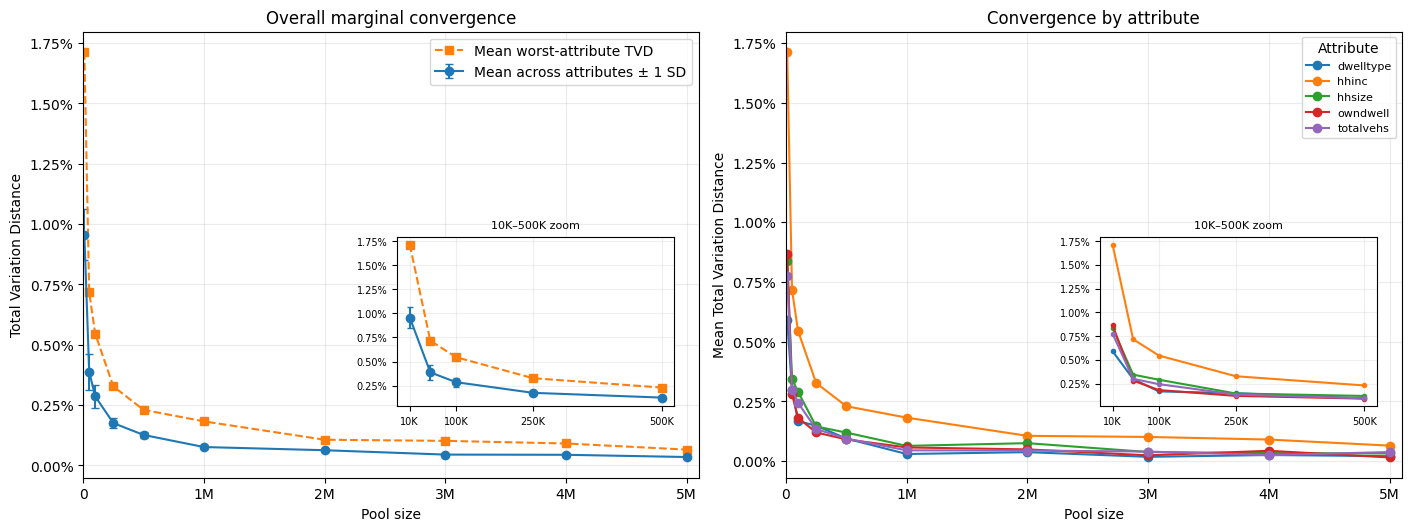

In [22]:
attribute_summary = (
    results.groupby(["pool_size", "attribute"], as_index=False)["tvd"]
    .mean()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), constrained_layout=True)
million_formatter = FuncFormatter(
    lambda value, _: "0" if value == 0 else f"{value / 1_000_000:g}M"
)

axes[0].errorbar(
    summary["pool_size"],
    summary["mean_tvd"],
    yerr=summary["sd_tvd"].fillna(0),
    marker="o",
    capsize=3,
    label="Mean across attributes ± 1 SD",
)
axes[0].plot(
    summary["pool_size"],
    summary["mean_maximum_tvd"],
    marker="s",
    linestyle="--",
    label="Mean worst-attribute TVD",
)
axes[0].set_title("Overall marginal convergence")
axes[0].set_xlabel("Pool size")
axes[0].set_ylabel("Total Variation Distance")
axes[0].set_xticks([0, 1_000_000, 2_000_000, 3_000_000, 4_000_000, 5_000_000])
axes[0].xaxis.set_major_formatter(million_formatter)
axes[0].set_xlim(0, 5_100_000)
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[0].grid(alpha=0.25)
axes[0].legend()

for attribute, group in attribute_summary.groupby("attribute"):
    axes[1].plot(
        group["pool_size"],
        group["tvd"],
        marker="o",
        label=attribute,
    )
axes[1].set_title("Convergence by attribute")
axes[1].set_xlabel("Pool size")
axes[1].set_ylabel("Mean Total Variation Distance")
axes[1].set_xticks([0, 1_000_000, 2_000_000, 3_000_000, 4_000_000, 5_000_000])
axes[1].xaxis.set_major_formatter(million_formatter)
axes[1].set_xlim(0, 5_100_000)
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))
axes[1].grid(alpha=0.25)
axes[1].legend(title="Attribute", fontsize=8)

early_summary = summary[summary["pool_size"] <= 500_000]
overall_inset = axes[0].inset_axes([0.51, 0.16, 0.45, 0.38])
overall_inset.errorbar(
    early_summary["pool_size"],
    early_summary["mean_tvd"],
    yerr=early_summary["sd_tvd"].fillna(0),
    marker="o",
    capsize=2,
)
overall_inset.plot(
    early_summary["pool_size"],
    early_summary["mean_maximum_tvd"],
    marker="s",
    linestyle="--",
)
overall_inset.set_title("10K–500K zoom", fontsize=8)
overall_inset.set_xticks([10_000, 100_000, 250_000, 500_000])
overall_inset.set_xticklabels(["10K", "100K", "250K", "500K"], fontsize=7)
overall_inset.yaxis.set_major_formatter(PercentFormatter(1.0))
overall_inset.tick_params(axis="y", labelsize=7)
overall_inset.grid(alpha=0.2)

early_attributes = attribute_summary[attribute_summary["pool_size"] <= 500_000]
attribute_inset = axes[1].inset_axes([0.51, 0.16, 0.45, 0.38])
for attribute, group in early_attributes.groupby("attribute"):
    attribute_inset.plot(group["pool_size"], group["tvd"], marker="o", markersize=3)
attribute_inset.set_title("10K–500K zoom", fontsize=8)
attribute_inset.set_xticks([10_000, 100_000, 250_000, 500_000])
attribute_inset.set_xticklabels(["10K", "100K", "250K", "500K"], fontsize=7)
attribute_inset.yaxis.set_major_formatter(PercentFormatter(1.0))
attribute_inset.tick_params(axis="y", labelsize=7)
attribute_inset.grid(alpha=0.2)

plt.show()

## Interpretation

Use the smallest candidate size for which:

1. Mean and worst-attribute TVD have visibly flattened.
2. The error bars are small relative to the preceding pool-size improvement.
3. `state_coverage_rate` is 100%, particularly for Negative income when it is enabled.

This provides a proportionate justification for the selected pool size without treating pool-size selection as a major methodological component.